## Import Packages

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import plotly

from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.metrics import (
    roc_auc_score, recall_score, accuracy_score, f1_score, precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

print("All core packages imported successfully.")

All core packages imported successfully.


In [2]:
from sklearn import set_config

from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

import optuna
from xgboost import XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore")
set_config(transform_output="pandas")

d:\Churn modelling\churn_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
from dotenv import load_dotenv
load_dotenv()

True

In [6]:
import os
import dagshub
import mlflow


# Set your DagsHub token as an env variable (avoids browser auth)
DAGSHUB_USER_TOKEN=os.getenv("DAGSHUB_USER_TOKEN")

dagshub.init(repo_owner='Ankitkumar1141', repo_name='Churn-modelling', mlflow=True)
mlflow.set_tracking_uri('https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow')
mlflow.set_experiment('Experiment 5 - XGB HP Tuning')
print('MLflow tracking active on DagsHub.')


❗❗❗ AUTHORIZATION REQUIRED ❗❗❗



Open the following link in your browser to authorize the client:
https://dagshub.com/login/oauth/authorize?state=ac9a7137-e140-430c-95ea-95b86d652299&client_id=32b60ba385aa7cecf24046d8195a71c07dd345d9657977863b52e7748e0f0f28&middleman_request_id=bb6b558de9c7b837c0a557ba38741e98b78ace1615467057229675e736e2619c




Accessing as Ankitkumar1141

Initialized MLflow to track repo "Ankitkumar1141/Churn-modelling"

Repository Ankitkumar1141/Churn-modelling initialized!

2026/10/13 21:01:57 INFO mlflow.tracking.fluent: Experiment with name 'Experiment 5 - XGB HP Tuning' does not exist. Creating a new experiment.


MLflow tracking active on DagsHub.


In [7]:
try:
    import mlflow
    mlflow.set_tracking_uri("https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow")
    mlflow.set_experiment("Experiment 5 - XGB HP Tuning")
    print("MLflow tracking active on DagsHub.")
except Exception as e:
    print(f"[MLflow Notice] {e}")

MLflow tracking active on DagsHub.


In [8]:
df = pd.read_csv("preprocessed.csv")
print("Loaded dataset shape:", df.shape)
df.head(3)

Loaded dataset shape: (10000, 37)


,customer_id,name,gender,age,salary,location_id,churned,account_id,tenure,balance,...,is_single_product,inactive_senior,engagement_score,high_risk_inactive,is_female,geo_france,geo_germany,geo_spain,geo_uk,geo_usa
0,15634602,Hargrave,female,42,101348.88,2,1,A15634602SID,2,NaN,...,1,0,0.750000,0,1,1,0,0,0,0
1,15647311,Hill,female,41,112542.58,6,0,A15647311SID,1,83807.86,...,1,0,0.416667,0,1,0,0,0,0,1
2,15619304,Onio,female,42,113931.57,4,1,A15619304SID,8,159660.80,...,0,0,0.583333,0,1,0,0,0,1,0


## Exploratory Checks

In [9]:
df.dtypes

customer_id                  int64
name                        object
gender                      object
age                          int64
salary                     float64
location_id                  int64
churned                      int64
account_id                  object
tenure                       int64
balance                    float64
num_products                 int64
has_credit_card              int64
is_active                    int64
geography                   object
age_group                   object
salary_bracket              object
tenure_group                object
has_balance                  int64
churn_label                 object
has_credit_card_label       object
is_active_label             object
balance_to_salary          float64
balance_per_product        float64
age_when_joined              int64
products_per_tenure        float64
is_senior_risk               int64
is_extreme_product_risk      int64
is_single_product            int64
inactive_senior     

In [10]:
df.isna().sum().sort_values(ascending=False).head(5)

balance        3617
name              0
gender            0
age               0
customer_id       0
dtype: int64

In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [12]:
print(df["churned"].value_counts())
churn_rate = df["churned"].mean()
print("\nChurn rate: {:.2%}".format(churn_rate))

churned
0    7963
1    2037
Name: count, dtype: int64

Churn rate: 20.37%


## Drop Unnecessary Columns

In [13]:
drop_columns = [
    "has_balance",
    "products_per_tenure",
    "has_credit_card",
    "geo_france", "geo_uk", "geo_usa", "geo_spain", "geo_germany",
    "tenure", "salary",
    "customer_id",
    "account_id", "name", "location_id",
    "age_when_joined", "age",
    "churn_label",
    "has_credit_card_label",
    "is_active_label",
]

df = df.drop(columns=drop_columns)
print("Shape after dropping columns:", df.shape)
df.head(3)

Shape after dropping columns: (10000, 18)


,gender,churned,balance,num_products,is_active,geography,age_group,salary_bracket,tenure_group,balance_to_salary,balance_per_product,is_senior_risk,is_extreme_product_risk,is_single_product,inactive_senior,engagement_score,high_risk_inactive,is_female
0,female,1,NaN,1,1,france,36-45,high,new (0-2),0.000000,0.000000,0,0,1,0,0.750000,0,1
1,female,0,83807.86,1,1,usa,36-45,high,new (0-2),0.744670,83807.860000,0,0,1,0,0.416667,0,1
2,female,1,159660.80,3,0,uk,36-45,high,veteran (8-10),1.401362,53220.266667,0,1,0,0,0.583333,0,1


In [14]:
missing_cols = df.isna().any(axis=0).loc[lambda x: x].index.tolist()
print("Columns with missing values:", missing_cols)

Columns with missing values: ['balance']


In [15]:
pct_missing_rows = df.isna().any(axis=1).mean().round(4) * 100
n_missing = df.isna().any(axis=1).sum()
print(f"Rows with missing values: {pct_missing_rows:.2f}%  ({n_missing:,} rows)")

Rows with missing values: 36.17%  (3,617 rows)


## Train / Test Split

In [16]:
X = df.drop(columns="churned")
y = df["churned"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Train size : {:,}  |  churn rate: {:.2%}".format(X_train.shape[0], y_train.mean()))
print("Test  size : {:,}  |  churn rate: {:.2%}".format(X_test.shape[0], y_test.mean()))

Train size : 8,000  |  churn rate: 20.38%
Test  size : 2,000  |  churn rate: 20.35%


In [17]:
print("Train shape:", X_train.shape)
print("Test  shape:", X_test.shape)
missing_in_train = X_train.isna().sum()
print("Missing in train (balance only):\n", missing_in_train[missing_in_train > 0])

Train shape: (8000, 17)
Test  shape: (2000, 17)
Missing in train (balance only):
 balance    2891
dtype: int64


## Column Type Identification

In [18]:
numeric_cols     = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
binary_cols      = [c for c in numeric_cols if X[c].nunique() == 2]
scale_cols       = [c for c in numeric_cols if c not in binary_cols]

print("Numeric (to scale) :", scale_cols)
print("Binary pass-thru   :", binary_cols)
print("Categorical OHE    :", categorical_cols)

Numeric (to scale) : ['balance', 'num_products', 'balance_to_salary', 'balance_per_product', 'engagement_score']
Binary pass-thru   : ['is_active', 'is_senior_risk', 'is_extreme_product_risk', 'is_single_product', 'inactive_senior', 'high_risk_inactive', 'is_female']
Categorical OHE    : ['gender', 'geography', 'age_group', 'salary_bracket', 'tenure_group']


## Preprocessing Pipeline

In [19]:
preprocessor = ColumnTransformer(
    transformers=[
        ("scale",          MinMaxScaler(), scale_cols),
        ("nominal_encode", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_cols),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)
preprocessor.set_output(transform="pandas")

knn_imputer = KNNImputer(n_neighbors=10)

In [20]:
# fit on train, transform test
base_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("knn_imputer",  knn_imputer),
])

X_train_trans = base_pipeline.fit_transform(X_train)
X_test_trans  = base_pipeline.transform(X_test)

print("X_train transformed shape:", X_train_trans.shape)
print("X_test  transformed shape:", X_test_trans.shape)

X_train transformed shape: (8000, 28)
X_test  transformed shape: (2000, 28)


In [21]:
sampler = RandomUnderSampler(random_state=42)

# Apply resampling to training data only (never to test set)
X_train_resampled, y_train_resampled = sampler.fit_resample(X_train_trans, y_train)

In [22]:
print("Before resampling — Train shape:", X_train_trans.shape)
print("Before resampling — Class distribution:")
print(y_train.value_counts())
print()
print("After  resampling — Train shape:", X_train_resampled.shape)
print("After  resampling — Class distribution:")
print(y_train_resampled.value_counts())

Before resampling — Train shape: (8000, 28)
Before resampling — Class distribution:
churned
0    6370
1    1630
Name: count, dtype: int64

After  resampling — Train shape: (3260, 28)
After  resampling — Class distribution:
churned
0    1630
1    1630
Name: count, dtype: int64


## XGBoost Hyperparameter Tuning with Optuna

Dedicated deep search across the **full XGBoost hyperparameter space**, building directly on the spot-check winner from Experiment 4.  
Each trial is logged as a nested MLflow run under **Experiment 5 — XGB HP Tuning**.  

**Primary metric: ROC-AUC** (maximised via 5-fold stratified CV on resampled training data).  

| Hyperparameter | Search Space | Description |
|---|---|---|
| `n_estimators` | 50 – 600 | Number of boosting rounds |
| `max_depth` | 2 – 12 | Max tree depth — controls complexity |
| `learning_rate` | 0.005 – 0.3 | Step-size shrinkage (η) |
| `subsample` | 0.5 – 1.0 | Row-sampling fraction per tree |
| `colsample_bytree` | 0.5 – 1.0 | Feature-sampling fraction per tree |
| `min_child_weight` | 1 – 10 | Min sum of instance weight in a leaf |
| `gamma` | 0.0 – 5.0 | Min loss reduction to make a split |
| `reg_alpha` | 1e-8 – 10.0 | L1 regularisation (log scale) |
| `reg_lambda` | 1e-8 – 10.0 | L2 regularisation (log scale) |

In [23]:
def objective(trial):
    with mlflow.start_run(nested=True):
        params = {
            "n_estimators"     : trial.suggest_int("n_estimators", 50, 600),
            "max_depth"        : trial.suggest_int("max_depth", 2, 12),
            "learning_rate"    : trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
            "subsample"        : trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree" : trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "min_child_weight" : trial.suggest_int("min_child_weight", 1, 10),
            "gamma"            : trial.suggest_float("gamma", 0.0, 5.0),
            "reg_alpha"        : trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
            "reg_lambda"       : trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
            "random_state"     : 42,
            "n_jobs"           : -1,
            "verbosity"        : 0,
            "eval_metric"      : "logloss",
        }

        # log all hyperparameters
        mlflow.log_params(params)

        # build the model
        xgb = XGBClassifier(**params)

        # 5-fold stratified cross-validation on resampled training data
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

        cv_scores = cross_validate(
            xgb,
            X_train_resampled,
            y_train_resampled,
            cv=cv,
            scoring={
                "roc_auc" : "roc_auc",
                "recall"  : "recall",
                "f1"      : "f1",
            },
            n_jobs=-1,
        )

        mean_roc_auc = cv_scores["test_roc_auc"].mean()
        mean_recall  = cv_scores["test_recall"].mean()
        mean_f1      = cv_scores["test_f1"].mean()

        # log CV metrics
        mlflow.log_metric("cv_mean_roc_auc", mean_roc_auc)
        mlflow.log_metric("cv_mean_recall",  mean_recall)
        mlflow.log_metric("cv_mean_f1",      mean_f1)

        return mean_roc_auc

In [24]:
# create optuna study
study = optuna.create_study(direction="maximize", study_name="xgb_hp_tuning")

with mlflow.start_run(run_name="XGB HP Tuning — Best Model") as parent:
    # optimize the objective function
    study.optimize(objective, n_trials=50, n_jobs=-1, show_progress_bar=True)

    # log the best parameters
    mlflow.log_params(study.best_params)

    # log the best score
    mlflow.log_metric("best_cv_roc_auc", study.best_value)

  0%|          | 0/50 [00:00<?, ?it/s]

🏃 View run masked-wasp-624 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4/runs/c55973ce044d4d5ba62c0ab8d9e3d465
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4


Best trial: 3. Best value: 0.842225:   2%|▏         | 1/50 [00:37<30:26, 37.28s/it]

🏃 View run tasteful-frog-152 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4/runs/01a6a80b22754acfb64cd6f0ae70143b
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4
🏃 View run caring-yak-567 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4/runs/dd1ad9dbe23742149523888d5bd247e9
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4
🏃 View run smiling-hen-466 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4/runs/c45aafd0f40f4467aca5403628a2a81b
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4
🏃 View run sedate-kit-44 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4/runs/f59d1f4830574c0680d43ea6abf831dd
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4
🏃 View run amazing-grouse-565 at: https://dag

Best trial: 4. Best value: 0.845212:   4%|▍         | 2/50 [01:13<29:13, 36.52s/it]

🏃 View run bouncy-midge-99 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4/runs/fec7ed5f630b4557b25100128b3a649a
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4


... (48 outputs left out)

Best trial: 42. Best value: 0.846088:  92%|█████████▏| 46/50 [09:01<00:29,  7.38s/it]

🏃 View run angry-steed-821 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4/runs/07f46edc4ae1470c871b7656ed75f6c2
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4
🏃 View run rebellious-hog-678 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4/runs/8cc542c017c34d44afffca6e630a6102
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4
🏃 View run sassy-tern-256 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4/runs/df062664001548abbb1dbbab838bb5d3
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4
🏃 View run carefree-rat-499 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4/runs/4e1e58e90dac4c62953377ef439b28ba
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4


Best trial: 49. Best value: 0.846354: 100%|██████████| 50/50 [09:25<00:00, 11.32s/it]


🏃 View run XGB HP Tuning — Best Model at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4/runs/3498c1bf91494390a920a75b1ccd70a6
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4


In [25]:
# best CV ROC-AUC achieved
print("Best CV ROC-AUC :", round(study.best_value, 4))

Best CV ROC-AUC : 0.8464


In [26]:
# best parameters
print("Best Parameters:")
for k, v in study.best_params.items():
    print(f"  {k:20s}: {v}")

Best Parameters:
  n_estimators        : 271
  max_depth           : 8
  learning_rate       : 0.025312410901151283
  subsample           : 0.8116685580007675
  colsample_bytree    : 0.5525301900542503
  min_child_weight    : 3
  gamma               : 4.808855231449563
  reg_alpha           : 0.006754532949638539
  reg_lambda          : 1.5508993409536373e-07


In [27]:
# dataframe of all trials
study.trials_dataframe().sort_values("value", ascending=False)

,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_alpha,params_reg_lambda,params_subsample,state
49,49,0.846354,2026-10-13 21:11:28.104534,2026-10-13 21:12:56.178719,0 days 00:01:28.074185,0.552530,4.808855,0.025312,8,3,271,6.754533e-03,1.550899e-07,0.811669,COMPLETE
42,42,0.846088,2026-10-13 21:10:07.704436,2026-10-13 21:12:27.778756,0 days 00:02:20.074320,0.549343,3.973842,0.015401,8,3,485,2.417646e-03,2.719062e-07,0.798903,COMPLETE
48,48,0.846065,2026-10-13 21:11:23.712337,2026-10-13 21:13:04.185600,0 days 00:01:40.473263,0.550509,4.909940,0.027386,8,3,253,1.470096e-02,1.099019e-07,0.811128,COMPLETE
34,34,0.845914,2026-10-13 21:08:27.650574,2026-10-13 21:11:28.102070,0 days 00:03:00.451496,0.520081,4.018225,0.013286,9,5,489,6.786749e-04,1.097983e-08,0.758326,COMPLETE
41,41,0.845891,2026-10-13 21:09:52.049189,2026-10-13 21:12:12.102834,0 days 00:02:20.053645,0.547310,3.995132,0.127534,8,3,484,2.794973e-03,1.323891e-07,0.810828,COMPLETE
39,39,0.845881,2026-10-13 21:09:27.712285,2026-10-13 21:11:36.194955,0 days 00:02:08.482670,0.506579,4.070522,0.014413,9,4,373,2.580777e-01,7.766878e-08,0.794189,COMPLETE
43,43,0.845771,2026-10-13 21:10:19.702807,2026-10-13 21:12:39.740282,0 days 00:02:20.037475,0.546480,3.954640,0.015986,11,3,480,2.186733e-03,1.555174e-07,0.814970,COMPLETE
27,27,0.845706,2026-10-13 21:07:09.220623,2026-10-13 21:09:52.046154,0 days 00:02:42.825531,0.513033,3.165044,0.013441,9,4,366,1.163338e-01,1.694176e-08,0.766619,COMPLETE
29,29,0.845668,2026-10-13 21:07:20.015050,2026-10-13 21:09:03.748062,0 days 00:01:43.733012,0.511190,3.975742,0.012010,10,5,471,5.020945e-04,1.681860e-03,0.769663,COMPLETE
28,28,0.845562,2026-10-13 21:07:16.829806,2026-10-13 21:07:59.696610,0 days 00:00:42.866804,0.511931,3.003512,0.012493,10,5,475,9.034069e-04,2.790022e-08,0.770346,COMPLETE


## Optuna Visualisations

In [28]:
# optimization history plot
optuna.visualization.plot_optimization_history(study)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'mode': 'markers',
              'name': 'Objective Value',
              'type': 'scatter',
              'x': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17,
                    18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
                    34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49],
              'y': [0.8127545259512967, 0.8425891076066092, 0.8446046144002409,
                    0.8422249614212053, 0.8452115247092475, 0.8444220708344311,
                    0.8439045504158983, 0.8455512062930483, 0.8157674357333734,
                    0.8402565019383491, 0.8392026421769732, 0.8374355451842372,
                    0.825556099213369, 0.8437483533441229, 0.8438452708043208,
                    0.8438433889118897, 0.8442348225375437, 0.8453865407053334,
                    0.8424884263615491, 0.8445434528962323, 0.8445641537129738,
                    0.8451870601076441, 0.8445020512627499, 0.8448671383943693,
                    0.8445283977567843, 0.8455126274982122, 0.8451004930558168,
                    0.8457055214723926, 0.8455615567014189, 0.8456678836237721,
                    0.8449292408445934, 0.8454514659942036, 0.8447372878166284,
                    0.8443552636531295, 0.8459144115322367, 0.8451607136136097,
                    0.8444644134141293, 0.8451597726673942, 0.8450261583047913,
                    0.8458814784146937, 0.8451654183446873, 0.8458908878768489,
                    0.846088486582107, 0.8457713877074786, 0.845243516880575,
                    0.8446601302269563, 0.8452792728367647, 0.8452199932251873,
                    0.8460649629267192, 0.846353833414882]},
             {'mode': 'lines',
              'name': 'Best Value',
              'type': 'scatter',
              'x': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17,
                    18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
                    34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49],
              'y': [0.8127545259512967, 0.8425891076066092, 0.8446046144002409,
                    0.8446046144002409, 0.8452115247092475, 0.8452115247092475,
                    0.8452115247092475, 0.8455512062930483, 0.8455512062930483,
                    0.8455512062930483, 0.8455512062930483, 0.8455512062930483,
                    0.8455512062930483, 0.8455512062930483, 0.8455512062930483,
                    0.8455512062930483, 0.8455512062930483, 0.8455512062930483,
                    0.8455512062930483, 0.8455512062930483, 0.8455512062930483,
                    0.8455512062930483, 0.8455512062930483, 0.8455512062930483,
                    0.8455512062930483, 0.8455512062930483, 0.8455512062930483,
                    0.8457055214723926, 0.8457055214723926, 0.8457055214723926,
                    0.8457055214723926, 0.8457055214723926, 0.8457055214723926,
                    0.8457055214723926, 0.8459144115322367, 0.8459144115322367,
                    0.8459144115322367, 0.8459144115322367, 0.8459144115322367,
                    0.8459144115322367, 0.8459144115322367, 0.8459144115322367,
                    0.846088486582107, 0.846088486582107, 0.846088486582107,
                    0.846088486582107, 0.846088486582107, 0.846088486582107,
                    0.846088486582107, 0.846353833414882]},
             {'marker': {'color': '#cccccc'},
              'mode': 'markers',
              'name': 'Infeasible Trial',
              'showlegend': False,
              'type': 'scatter',
              'x': [],
              'y': []}],
    'layout': {'template': '...',
               'title': {'text': 'Optimization History Plot'},
               'xaxis': {'title': {'text': 'Trial'}},
               'yaxis': {'title': {'text': 'Objective Value'}}}
})

In [29]:
# hyperparameter importance plot
optuna.visualization.plot_param_importances(study)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'cliponaxis': False,
              'hovertemplate': [reg_alpha (FloatDistribution):
                                0.0012427577554321165<extra></extra>, reg_lambda
                                (FloatDistribution):
                                0.007721661503426612<extra></extra>, subsample
                                (FloatDistribution):
                                0.013099462411513167<extra></extra>, max_depth
                                (IntDistribution):
                                0.029765595847184245<extra></extra>,
                                colsample_bytree (FloatDistribution):
                                0.03281437065638647<extra></extra>,
                                min_child_weight (IntDistribution):
                                0.09487931972196928<extra></extra>, gamma
                                (FloatDistribution):
                                0.09760616499223922<extra></extra>, n_estimators
                                (IntDistribution):
                                0.29135647820658034<extra></extra>, learning_rate
                                (FloatDistribution):
                                0.4315141889052687<extra></extra>],
              'name': 'Objective Value',
              'orientation': 'h',
              'text': [<0.01, <0.01, 0.01, 0.03, 0.03, 0.09, 0.10, 0.29, 0.43],
              'textposition': 'outside',
              'type': 'bar',
              'x': [0.0012427577554321165, 0.007721661503426612,
                    0.013099462411513167, 0.029765595847184245,
                    0.03281437065638647, 0.09487931972196928, 0.09760616499223922,
                    0.29135647820658034, 0.4315141889052687],
              'y': [reg_alpha, reg_lambda, subsample, max_depth, colsample_bytree,
                    min_child_weight, gamma, n_estimators, learning_rate]}],
    'layout': {'template': '...',
               'title': {'text': 'Hyperparameter Importances'},
               'xaxis': {'title': {'text': 'Hyperparameter Importance'}},
               'yaxis': {'title': {'text': 'Hyperparameter'}}}
})

In [30]:
# slice plot -- individual parameter effect on objective
optuna.visualization.plot_slice(study)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'marker': {'color': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,
                                   14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25,
                                   26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37,
                                   38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49],
                         'colorbar': {'title': {'text': 'Trial'}, 'x': 1.0, 'xpad': 40},
                         'colorscale': [[0.0, 'rgb(247,251,255)'], [0.125,
                                        'rgb(222,235,247)'], [0.25,
                                        'rgb(198,219,239)'], [0.375,
                                        'rgb(158,202,225)'], [0.5,
                                        'rgb(107,174,214)'], [0.625,
                                        'rgb(66,146,198)'], [0.75,
                                        'rgb(33,113,181)'], [0.875,
                                        'rgb(8,81,156)'], [1.0, 'rgb(8,48,107)']],
                         'line': {'color': 'Grey', 'width': 0.5},
                         'showscale': True},
              'mode': 'markers',
              'name': 'Feasible Trial',
              'showlegend': False,
              'type': 'scatter',
              'x': [0.5946876292213965, 0.9268893192793468, 0.7817565535635886,
                    0.995192869263821, 0.6270361516014771, 0.8886658854544518,
                    0.8279419165881383, 0.6644772418874765, 0.9933521690804763,
                    0.6282501203437623, 0.5582729759748346, 0.5796565919109578,
                    0.8143210584883384, 0.8607062832333583, 0.6260580144114296,
                    0.6922715636846177, 0.6060919510436564, 0.6898706322258199,
                    0.6054054815860653, 0.6940903448703452, 0.6974179904167433,
                    0.6956503981824517, 0.6937401705486294, 0.681432713315187,
                    0.6829862516760948, 0.6963677903332597, 0.5019630340102295,
                    0.5130325587451862, 0.511931085795726, 0.5111896358034461,
                    0.7778282019752425, 0.5093772326236146, 0.7557421043214376,
                    0.5189993220371711, 0.5200812917143451, 0.5103782747255712,
                    0.5044082028664585, 0.5143913977554198, 0.5154956878705601,
                    0.5065786695837922, 0.538928171994202, 0.5473100084458237,
                    0.5493426780616764, 0.5464804631379621, 0.5416031101355954,
                    0.5541704453859335, 0.5409453601230905, 0.5512895908961584,
                    0.5505094774266017, 0.5525301900542503],
              'xaxis': 'x',
              'y': [0.8127545259512967, 0.8425891076066092, 0.8446046144002409,
                    0.8422249614212053, 0.8452115247092475, 0.8444220708344311,
                    0.8439045504158983, 0.8455512062930483, 0.8157674357333734,
                    0.8402565019383491, 0.8392026421769732, 0.8374355451842372,
                    0.825556099213369, 0.8437483533441229, 0.8438452708043208,
                    0.8438433889118897, 0.8442348225375437, 0.8453865407053334,
                    0.8424884263615491, 0.8445434528962323, 0.8445641537129738,
                    0.8451870601076441, 0.8445020512627499, 0.8448671383943693,
                    0.8445283977567843, 0.8455126274982122, 0.8451004930558168,
                    0.8457055214723926, 0.8455615567014189, 0.8456678836237721,
                    0.8449292408445934, 0.8454514659942036, 0.8447372878166284,
                    0.8443552636531295, 0.8459144115322367, 0.8451607136136097,
                    0.8444644134141293, 0.8451597726673942, 0.8450261583047913,
                    0.8458814784146937, 0.8451654183446873, 0.8458908878768489,
                    0.846088486582107, 0.8457713877074786, 0.845243516880575,
                    0.8446601302269563, 0.8452792728367647, 0.8452199932251873,
                    0.8460649629267192, 0.846353833414882],
              'yaxis': 'y'},
             {'marker'

In [31]:
# parallel coordinate plot -- interactions between key params
optuna.visualization.plot_parallel_coordinate(
    study,
    params=["n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree"]
)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'dimensions': [{'label': 'Objective Value',
                              'range': [0.8127545259512967, 0.846353833414882],
                              'values': [0.8127545259512967, 0.8425891076066092,
                                         0.8446046144002409, 0.8422249614212053,
                                         0.8452115247092475, 0.8444220708344311,
                                         0.8439045504158983, 0.8455512062930483,
                                         0.8157674357333734, 0.8402565019383491,
                                         0.8392026421769732, 0.8374355451842372,
                                         0.825556099213369, 0.8437483533441229,
                                         0.8438452708043208, 0.8438433889118897,
                                         0.8442348225375437, 0.8453865407053334,
                                         0.8424884263615491, 0.8445434528962323,
                                         0.8445641537129738, 0.8451870601076441,
                                         0.8445020512627499, 0.8448671383943693,
                                         0.8445283977567843, 0.8455126274982122,
                                         0.8451004930558168, 0.8457055214723926,
                                         0.8455615567014189, 0.8456678836237721,
                                         0.8449292408445934, 0.8454514659942036,
                                         0.8447372878166284, 0.8443552636531295,
                                         0.8459144115322367, 0.8451607136136097,
                                         0.8444644134141293, 0.8451597726673942,
                                         0.8450261583047913, 0.8458814784146937,
                                         0.8451654183446873, 0.8458908878768489,
                                         0.846088486582107, 0.8457713877074786,
                                         0.845243516880575, 0.8446601302269563,
                                         0.8452792728367647, 0.8452199932251873,
                                         0.8460649629267192, 0.846353833414882]},
                             {'label': 'colsample_bytree',
                              'range': [0.5019630340102295, 0.995192869263821],
                              'values': [0.5946876292213965, 0.9268893192793468,
                                         0.7817565535635886, 0.995192869263821,
                                         0.6270361516014771, 0.8886658854544518,
                                         0.8279419165881383, 0.6644772418874765,
                                         0.9933521690804763, 0.6282501203437623,
                                         0.5582729759748346, 0.5796565919109578,
                                         0.8143210584883384, 0.8607062832333583,
                                         0.6260580144114296, 0.6922715636846177,
                                         0.6060919510436564, 0.6898706322258199,
                                         0.6054054815860653, 0.6940903448703452,
                                         0.6974179904167433, 0.6956503981824517,
                                         0.6937401705486294, 0.681432713315187,
                                         0.6829862516760948, 0.6963677903332597,
                                         0.5019630340102295, 0.5130325587451862,
                                         0.511931085795726, 0.5111896358034461,
                                         0.7778282019752425, 0.5093772326236146,
                                         0.7557421043214376, 0.5189993220371711,
                                         0.5200812917143451, 0.5103782747255712,
                                         0.5044082028664585, 0.5143913977554198,
                                         0.5154956878705601, 0.5065786695837922,
                                         0.538928171994202, 0.547310008445

## Train Best Model & Evaluate on Test Set

In [32]:
# build best XGBoost model with tuned parameters
best_params = study.best_params.copy()
best_params.update({
    "random_state" : 42,
    "n_jobs"       : -1,
    "verbosity"    : 0,
    "eval_metric"  : "logloss",
})

best_xgb = XGBClassifier(**best_params)

# train on resampled data
best_xgb.fit(X_train_resampled, y_train_resampled)
print("Best XGBoost model trained.")

Best XGBoost model trained.


In [33]:
# predictions on full train + test (pre-transformed, unresampled)
y_pred_train = best_xgb.predict(X_train_trans)
y_pred_test  = best_xgb.predict(X_test_trans)
y_prob_train = best_xgb.predict_proba(X_train_trans)[:, 1]
y_prob_test  = best_xgb.predict_proba(X_test_trans)[:, 1]

train_acc = accuracy_score(y_train, y_pred_train)
test_acc  = accuracy_score(y_test, y_pred_test)
train_rec = recall_score(y_train, y_pred_train)
test_rec  = recall_score(y_test, y_pred_test)
train_auc = roc_auc_score(y_train, y_prob_train)
test_auc  = roc_auc_score(y_test, y_prob_test)

print(f"Train accuracy : {train_acc:.4f}")
print(f"Test  accuracy : {test_acc:.4f}")
print(f"Train recall   : {train_rec:.4f}")
print(f"Test  recall   : {test_rec:.4f}")
print(f"Train ROC-AUC  : {train_auc:.4f}")
print(f"Test  ROC-AUC  : {test_auc:.4f}")

Train accuracy : 0.7785
Test  accuracy : 0.7725
Train recall   : 0.7626
Test  recall   : 0.7518
Train ROC-AUC  : 0.8578
Test  ROC-AUC  : 0.8492


In [34]:
print("\n=== Classification Report (Test Set) ===")
print(classification_report(y_test, y_pred_test, target_names=["Stayed", "Churned"]))


=== Classification Report (Test Set) ===
              precision    recall  f1-score   support

      Stayed       0.92      0.78      0.84      1593
     Churned       0.46      0.75      0.57       407

    accuracy                           0.77      2000
   macro avg       0.69      0.76      0.71      2000
weighted avg       0.83      0.77      0.79      2000



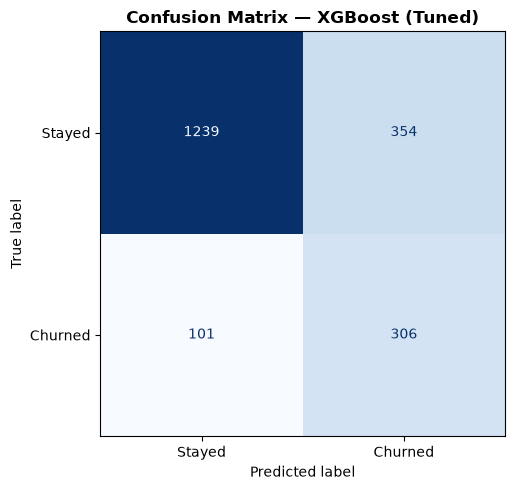

In [35]:
# Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Stayed", "Churned"])
disp.plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Confusion Matrix — XGBoost (Tuned)", fontweight="bold")
plt.tight_layout()
plt.show()

## Cross-Validation

In [36]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "roc_auc"  : "roc_auc",
    "recall"   : "recall",
    "precision": "precision",
    "f1"       : "f1",
    "accuracy" : "accuracy",
}

In [37]:
# Full pipeline: preprocessor + KNN imputer + resampler + best XGB
cv_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("knn_imputer",  KNNImputer(n_neighbors=10)),
    ("sampler",      RandomUnderSampler(random_state=42)),
    ("classifier",   best_xgb),
])

cv_results = cross_validate(
    cv_pipeline,
    X_train,       # raw X_train — pipeline handles everything inside each fold
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=1,
)

results_df = pd.DataFrame(cv_results)
results_df

,fit_time,score_time,test_roc_auc,test_recall,test_precision,test_f1,test_accuracy
0,1.660069,0.729054,0.840916,0.723926,0.459144,0.561905,0.770000
1,1.551601,0.734952,0.854831,0.757669,0.450730,0.565217,0.762500
2,1.557045,0.756103,0.838962,0.708589,0.435028,0.539090,0.753125
3,1.626761,0.723783,0.818448,0.696319,0.453094,0.548972,0.766875
4,1.527873,0.760952,0.841264,0.717791,0.464286,0.563855,0.773750


In [38]:
print("=== CV Summary (5-Fold Stratified) ===")
print(f"Mean CV ROC-AUC  : {results_df['test_roc_auc'].mean():.4f} +/- {results_df['test_roc_auc'].std():.4f}")
print(f"Mean CV Recall   : {results_df['test_recall'].mean():.4f} +/- {results_df['test_recall'].std():.4f}")
print(f"Mean CV Precision: {results_df['test_precision'].mean():.4f} +/- {results_df['test_precision'].std():.4f}")
print(f"Mean CV F1       : {results_df['test_f1'].mean():.4f} +/- {results_df['test_f1'].std():.4f}")
print(f"Mean CV Accuracy : {results_df['test_accuracy'].mean():.4f} +/- {results_df['test_accuracy'].std():.4f}")

=== CV Summary (5-Fold Stratified) ===
Mean CV ROC-AUC  : 0.8389 +/- 0.0131
Mean CV Recall   : 0.7209 +/- 0.0231
Mean CV Precision: 0.4525 +/- 0.0111
Mean CV F1       : 0.5558 +/- 0.0114
Mean CV Accuracy : 0.7653 +/- 0.0079


## Log Experiment to MLflow

In [39]:
try:
    with mlflow.start_run(run_name="XGB HP Tuning — Final Evaluation"):
        mlflow.log_param("experiment_type",    "XGB Hyperparameter Tuning")
        mlflow.log_param("imbalance_strategy", "RandomUnderSampler")
        mlflow.log_param("imputer",            "KNNImputer(n_neighbors=10)")
        mlflow.log_param("n_optuna_trials",    50)
        mlflow.log_param("dataset_rows",       X.shape[0])
        mlflow.log_param("dataset_features",   X.shape[1])
        mlflow.log_params(best_params)

        mlflow.log_metric("training_accuracy", accuracy_score(y_train, y_pred_train))
        mlflow.log_metric("training_recall",   recall_score(y_train, y_pred_train))
        mlflow.log_metric("training_roc_auc",  roc_auc_score(y_train, y_prob_train))
        mlflow.log_metric("test_accuracy",     accuracy_score(y_test, y_pred_test))
        mlflow.log_metric("test_recall",       recall_score(y_test, y_pred_test))
        mlflow.log_metric("test_precision",    precision_score(y_test, y_pred_test))
        mlflow.log_metric("test_f1",           f1_score(y_test, y_pred_test))
        mlflow.log_metric("test_roc_auc",      roc_auc_score(y_test, y_prob_test))
        mlflow.log_metric("cv_mean_recall",    results_df['test_recall'].mean())
        mlflow.log_metric("cv_mean_roc_auc",   results_df['test_roc_auc'].mean())
        mlflow.log_metric("cv_mean_f1",        results_df['test_f1'].mean())
        mlflow.log_metric("optuna_best_cv_roc_auc", study.best_value)

        for i, s in enumerate(results_df['test_roc_auc']):
            mlflow.log_metric("cv_roc_auc_fold", s, step=i)
        for i, s in enumerate(results_df['test_recall']):
            mlflow.log_metric("cv_recall_fold", s, step=i)

        # log model artifact
        signature = mlflow.models.infer_signature(
            model_input=X_train_resampled.sample(20, random_state=42),
            model_output=best_xgb.predict_proba(X_train_resampled.sample(20, random_state=42))[:, 1],
        )
        mlflow.sklearn.log_model(best_xgb, artifact_path="xgb_tuned_model", signature=signature)

    print("Experiment logged to MLflow.")
except Exception as e:
    print(f"[MLflow Notice] {e}")

2026/10/13 21:16:53 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run XGB HP Tuning — Final Evaluation at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4/runs/8cf345c37c4645c89a4f09eeb824ae97
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/4
[MLflow Notice] The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['xgboost.core.Booster', 'xgboost.sklearn.XGBClassifier'].


## Final Summary

In [40]:
summary = pd.DataFrame({
    "Metric": [
        "Test ROC-AUC", "Test Recall", "Test Precision", "Test F1", "Test Accuracy",
        "CV ROC-AUC (mean)", "CV Recall (mean)", "CV F1 (mean)", "CV Accuracy (mean)",
    ],
    "Exp 4: XGB Spot-Check (Baseline)": [
        0.8473, 0.7224, 0.4696, 0.5692, 0.7775,
        0.8368, 0.7178, 0.5607, None,
    ],
    "Exp 5: XGB HP Tuning (This Notebook)": [
        round(roc_auc_score(y_test, y_prob_test),           4),
        round(recall_score(y_test, y_pred_test),            4),
        round(precision_score(y_test, y_pred_test),         4),
        round(f1_score(y_test, y_pred_test),                4),
        round(accuracy_score(y_test, y_pred_test),          4),
        round(results_df['test_roc_auc'].mean(),            4),
        round(results_df['test_recall'].mean(),             4),
        round(results_df['test_f1'].mean(),                 4),
        round(results_df['test_accuracy'].mean(),           4),
    ]
})
summary

,Metric,Exp 4: XGB Spot-Check (Baseline),Exp 5: XGB HP Tuning (This Notebook)
0,Test ROC-AUC,0.8473,0.8492
1,Test Recall,0.7224,0.7518
2,Test Precision,0.4696,0.4636
3,Test F1,0.5692,0.5736
4,Test Accuracy,0.7775,0.7725
5,CV ROC-AUC (mean),0.8368,0.8389
6,CV Recall (mean),0.7178,0.7209
7,CV F1 (mean),0.5607,0.5558
8,CV Accuracy (mean),NaN,0.7653


In [41]:
print(f">>> Optuna best CV ROC-AUC : {study.best_value:.4f}")
print(f">>> Test  ROC-AUC (tuned)  : {roc_auc_score(y_test, y_prob_test):.4f}")
print(f">>> Test  Recall   (tuned) : {recall_score(y_test, y_pred_test):.4f}")
print(f">>> Test  F1       (tuned) : {f1_score(y_test, y_pred_test):.4f}")
print()
print(">>> Best Hyperparameters:")
for k, v in study.best_params.items():
    print(f"    {k:20s}: {v}")
print()
print(">>> Next: 07_Churn_LGBM_HP_Tuning.ipynb")

>>> Optuna best CV ROC-AUC : 0.8464
>>> Test  ROC-AUC (tuned)  : 0.8492
>>> Test  Recall   (tuned) : 0.7518
>>> Test  F1       (tuned) : 0.5736

>>> Best Hyperparameters:
    n_estimators        : 271
    max_depth           : 8
    learning_rate       : 0.025312410901151283
    subsample           : 0.8116685580007675
    colsample_bytree    : 0.5525301900542503
    min_child_weight    : 3
    gamma               : 4.808855231449563
    reg_alpha           : 0.006754532949638539
    reg_lambda          : 1.5508993409536373e-07

>>> Next: 07_Churn_LGBM_HP_Tuning.ipynb
